# 01 — EDA (TV1, Việc 4)

**Add Input:** Kaggle Dataset `nhom05-falldet-processed` (tạo từ `00_prepare_data.ipynb`). Bật **Internet**, không cần GPU.

**Trước khi chạy:** code mới nhất đã được commit và push lên nhánh `tv1/gk-data-eda-m1`.

Đầu ra: các biểu đồ `eda_*.png` trong `reports/figures/` (dpi 200), bảng và số đo trong `reports/results/`, hình minh họa augmentation, và `DATA_CARD.md` có thêm khối kích thước khung hình.

In [5]:
# Ô đầu tiên: lấy mã nguồn, cố định seed, in version Python, torch, ultralytics, opencv và version dataset.
# Cần bật Internet để clone repo. Nếu thư mục đã có (chạy lại trong cùng phiên) thì pull để lấy code mới.
import os, sys
BRANCH = "main"  # đổi thành "main" sau khi PR #2 được merge
REPO = "/kaggle/working/FallDetection"
if not os.path.exists(REPO):
    !git clone --depth 1 -b {BRANCH} https://github.com/ducqwang/FallDetection.git {REPO}
else:
    !git -C {REPO} pull
%cd {REPO}
!pip install -q ultralytics==8.4.202 lap==0.5.14
sys.path.insert(0, REPO)
from src.data.env_info import setup_notebook
setup_notebook("configs/data.yaml", seed=42)

remote: Enumerating objects: 28, done.
remote: Counting objects: 100% (28/28), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 15 (delta 13), reused 14 (delta 13), pack-reused 0 (from 0)
Unpacking objects: 100% (15/15), 4.43 KiB | 647.00 KiB/s, done.
From https://github.com/ducqwang/FallDetection
   5a81e1b..91dcf0b  main       -> origin/main
Updating 5a81e1b..91dcf0b
Fast-forward
 docs/HANDOFF_TV1.md        |  5 +++++
 notebooks/tv1_01_eda.ipynb |  2 +-
 src/eda/plots.py           | 12 +++++++++---
 src/models/m1_features.py  | 11 +++++++++++
 src/models/m1_rule.py      | 10 +++++++---
 tests/test_frame_size.py   | 28 ++++++++++++++++++++++++++++
 6 files changed, 61 insertions(+), 7 deletions(-)
/kaggle/working/FallDetection
seed = 42 | Python 3.13.16
torch: 2.11.0+cu130
ultralytics: 8.4.202
opencv: 4.14.0
dataset urfd_images: https://www.kaggle.com/datasets/shahliza27/ur-fall-detection-dataset | version: 1
dataset urfd_labels: https://www.kaggle.com/datasets/minhq

In [6]:
from pathlib import Path
from src.data.loader import data_root, load_metadata
ROOT = data_root()
print("Dữ liệu:", ROOT)
meta = load_metadata(ROOT)
print(meta.groupby(["dataset", "scene"]).size())

Dữ liệu: /kaggle/input/notebooks/minhquang2701/nhom05-falldet-processed/nhom05-falldet-processed
dataset  scene      
le2i     coffee_room    70
         home           60
urfd     urfd           70
dtype: int64


## Biểu đồ EDA

Biểu đồ 1–4 chỉ đọc `metadata.csv`. Biểu đồ 5 dùng đặc trưng hình học theo cửa sổ từ Le2i GT bbox, vẽ hai bản: 5 tô theo lớp, 5b tô theo kích thước khung (320×180 / 320×240). Biểu đồ 6 và `reports/results/le2i_scene_size_table.csv` là bảng scene × kích thước × lớp. Khối cảnh báo kích thước được ghi vào `DATA_CARD.md` (không có `--data-card` thì bỏ qua). Khi có tracks cache, thêm `--tracks <đường dẫn>`.

In [7]:
# Lấy DATA_CARD.md đầy đủ do prepare_data sinh ra, để EDA chỉ ghi thêm khối kích thước vào đó (không tạo file rỗng).
!cp {ROOT}/DATA_CARD.md DATA_CARD.md
!python -m src.eda.plots --meta {ROOT}/metadata.csv --gt-bbox {ROOT}/annotations/le2i_gt_bbox.csv --out-dir reports/figures --window-s 1.0 --stride-s 0.25 --perplexity 30 --seed 42 --results-dir reports/results --data-card DATA_CARD.md

CẢNH BÁO | Le2i GT: bỏ 350 dòng bbox trùng (video_id, frame_idx), giữ dòng đầu
ĐỘ TÁCH THEO KÍCH THƯỚC | {'n_windows': 6550, 'sizes': [np.str_('320×180'), np.str_('320×240')], 'silhouette_size': 0.11447378395897784, 'centroid_distance': 0.33794373378760456, 'silhouette_size_fall': 0.011542119217977634, 'silhouette_label': 0.5210650574855021}
TÓM TẮT | video trong metadata: 200 | cửa sổ: 6550 (té ngã 469) | bỏ qua ở biểu đồ 1-3, 5: 0 (has_event_label = 0) | Đã ghi: reports/figures/eda_1_clip_counts.png, reports/figures/eda_2_duration.png, reports/figures/eda_3_frame_balance.png, reports/figures/eda_4_scene_distribution.png, reports/figures/eda_6_le2i_scene_size.png, reports/results/le2i_scene_size_table.csv, reports/figures/eda_5_pca_tsne.png, reports/figures/eda_5b_pca_tsne_by_size.png, reports/results/size_separation.json, DATA_CARD.md


eda_1_clip_counts.png


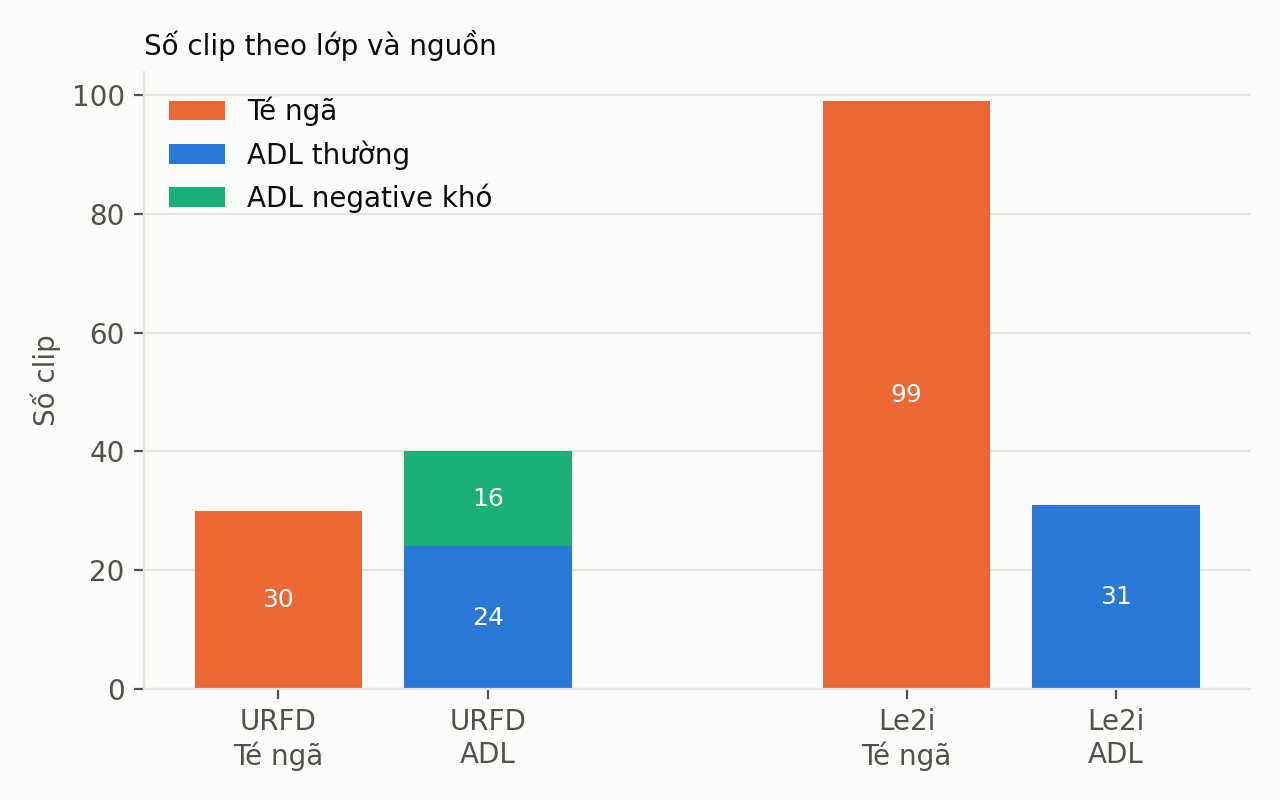

eda_2_duration.png


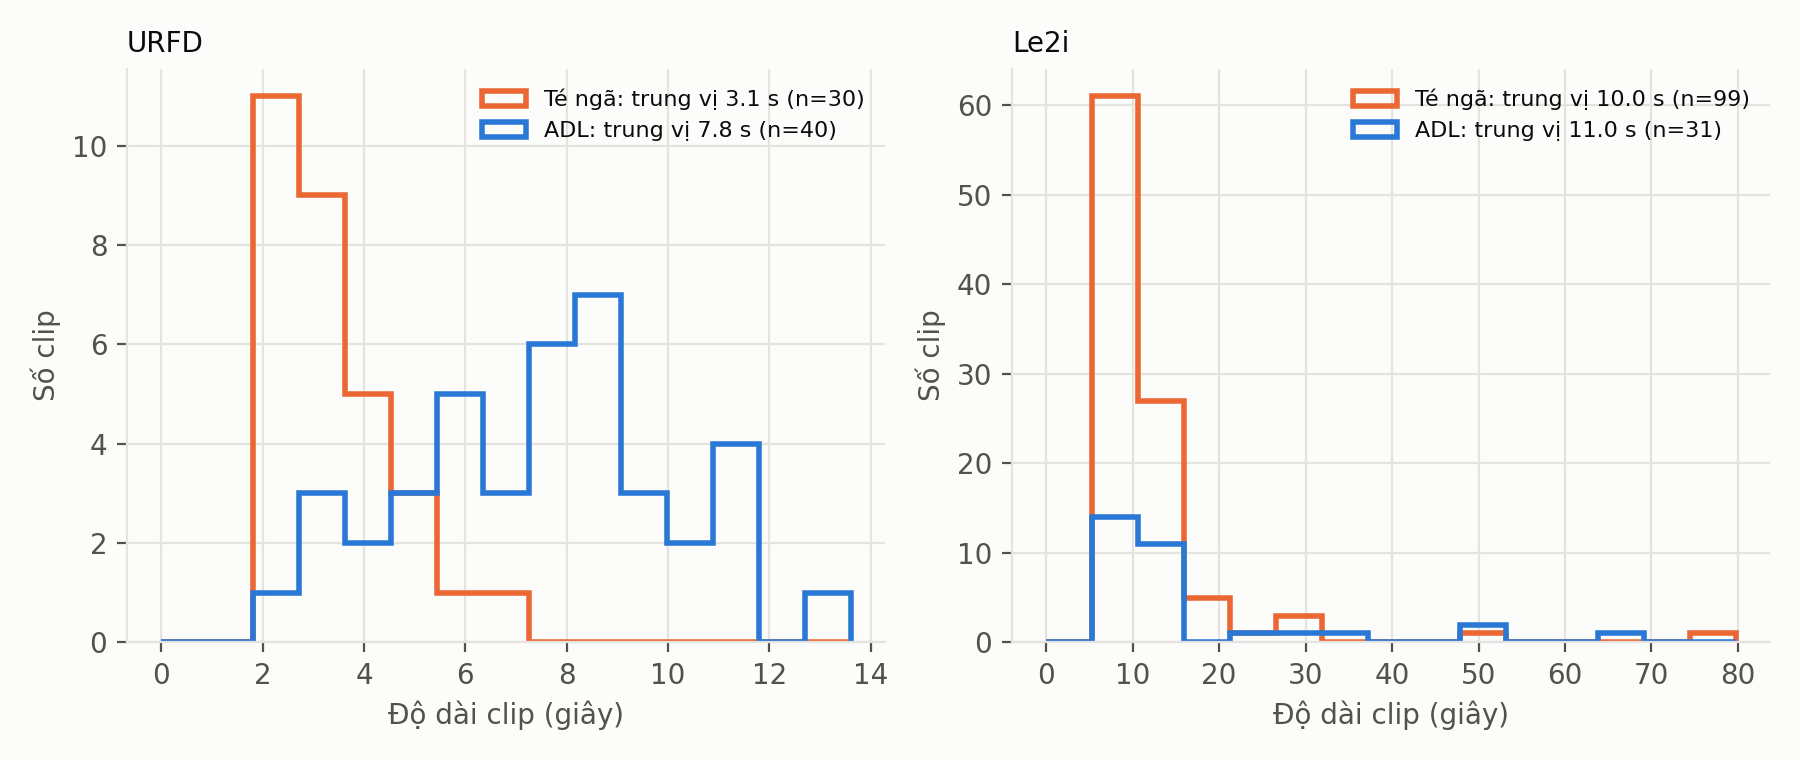

eda_3_frame_balance.png


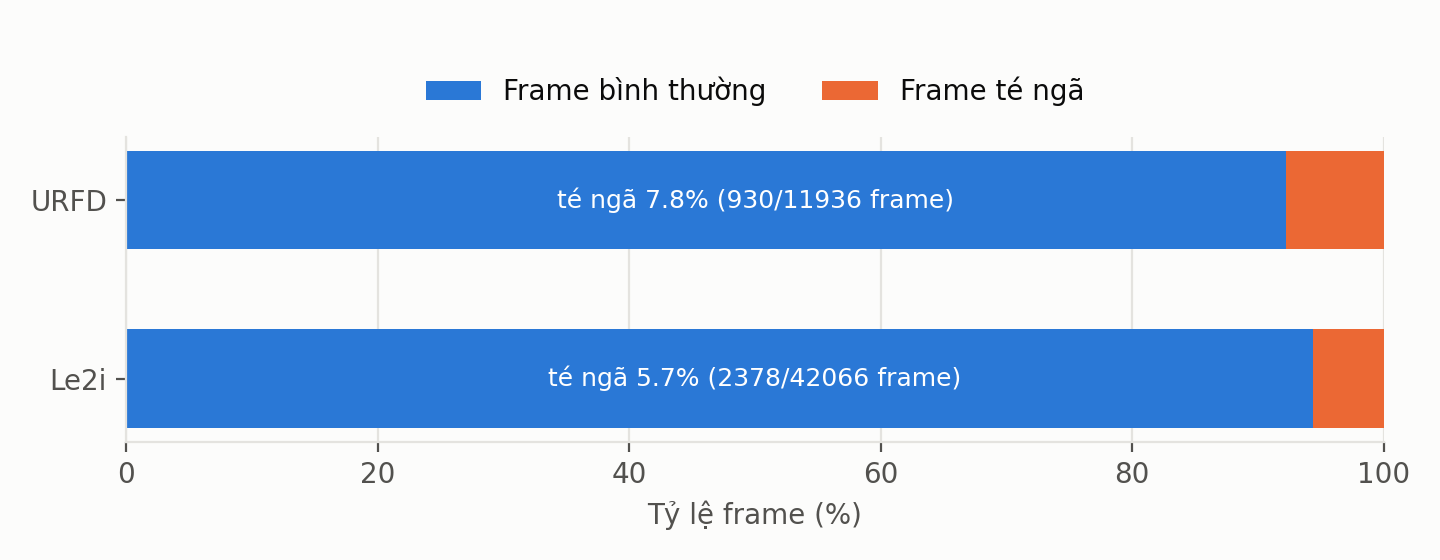

eda_4_scene_distribution.png


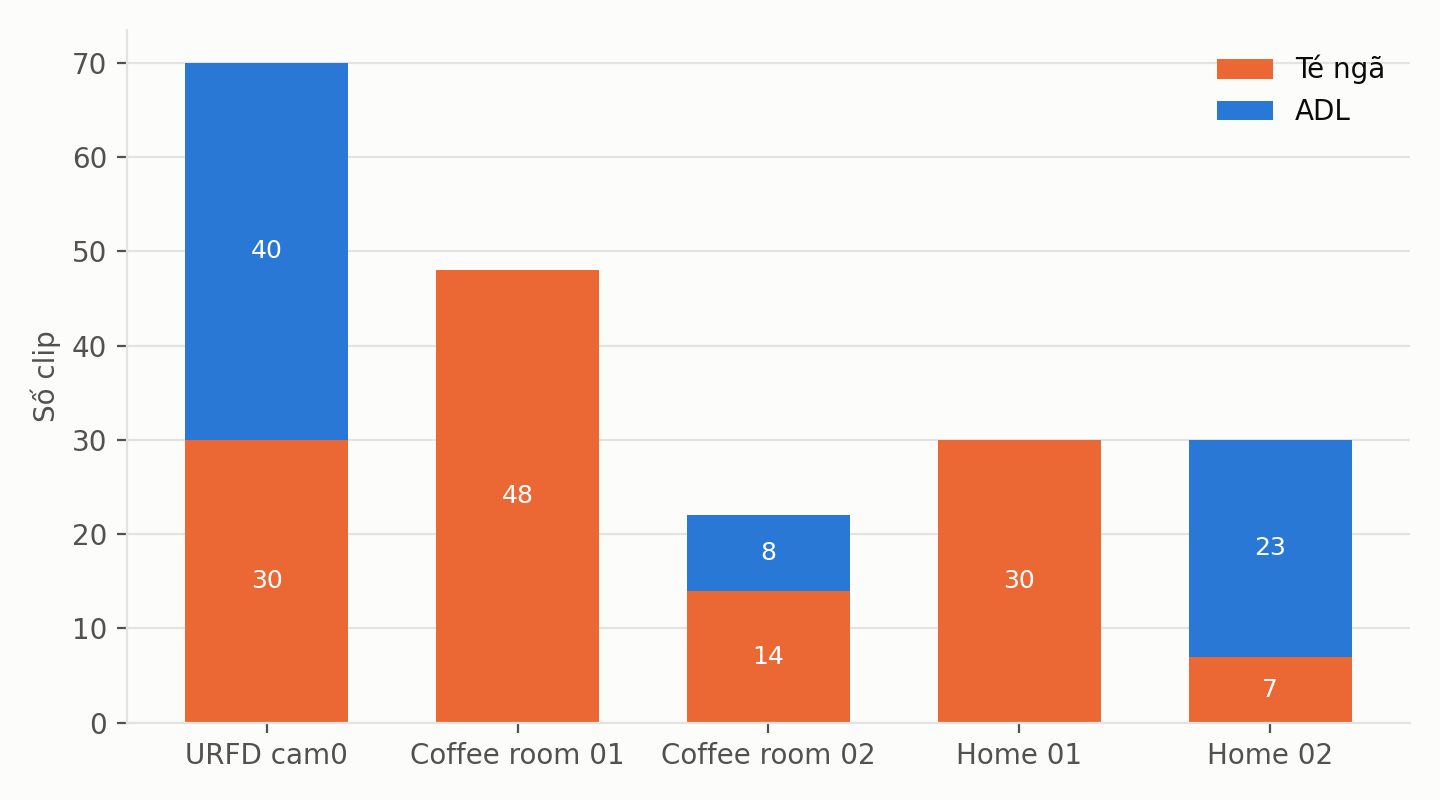

eda_5_pca_tsne.png


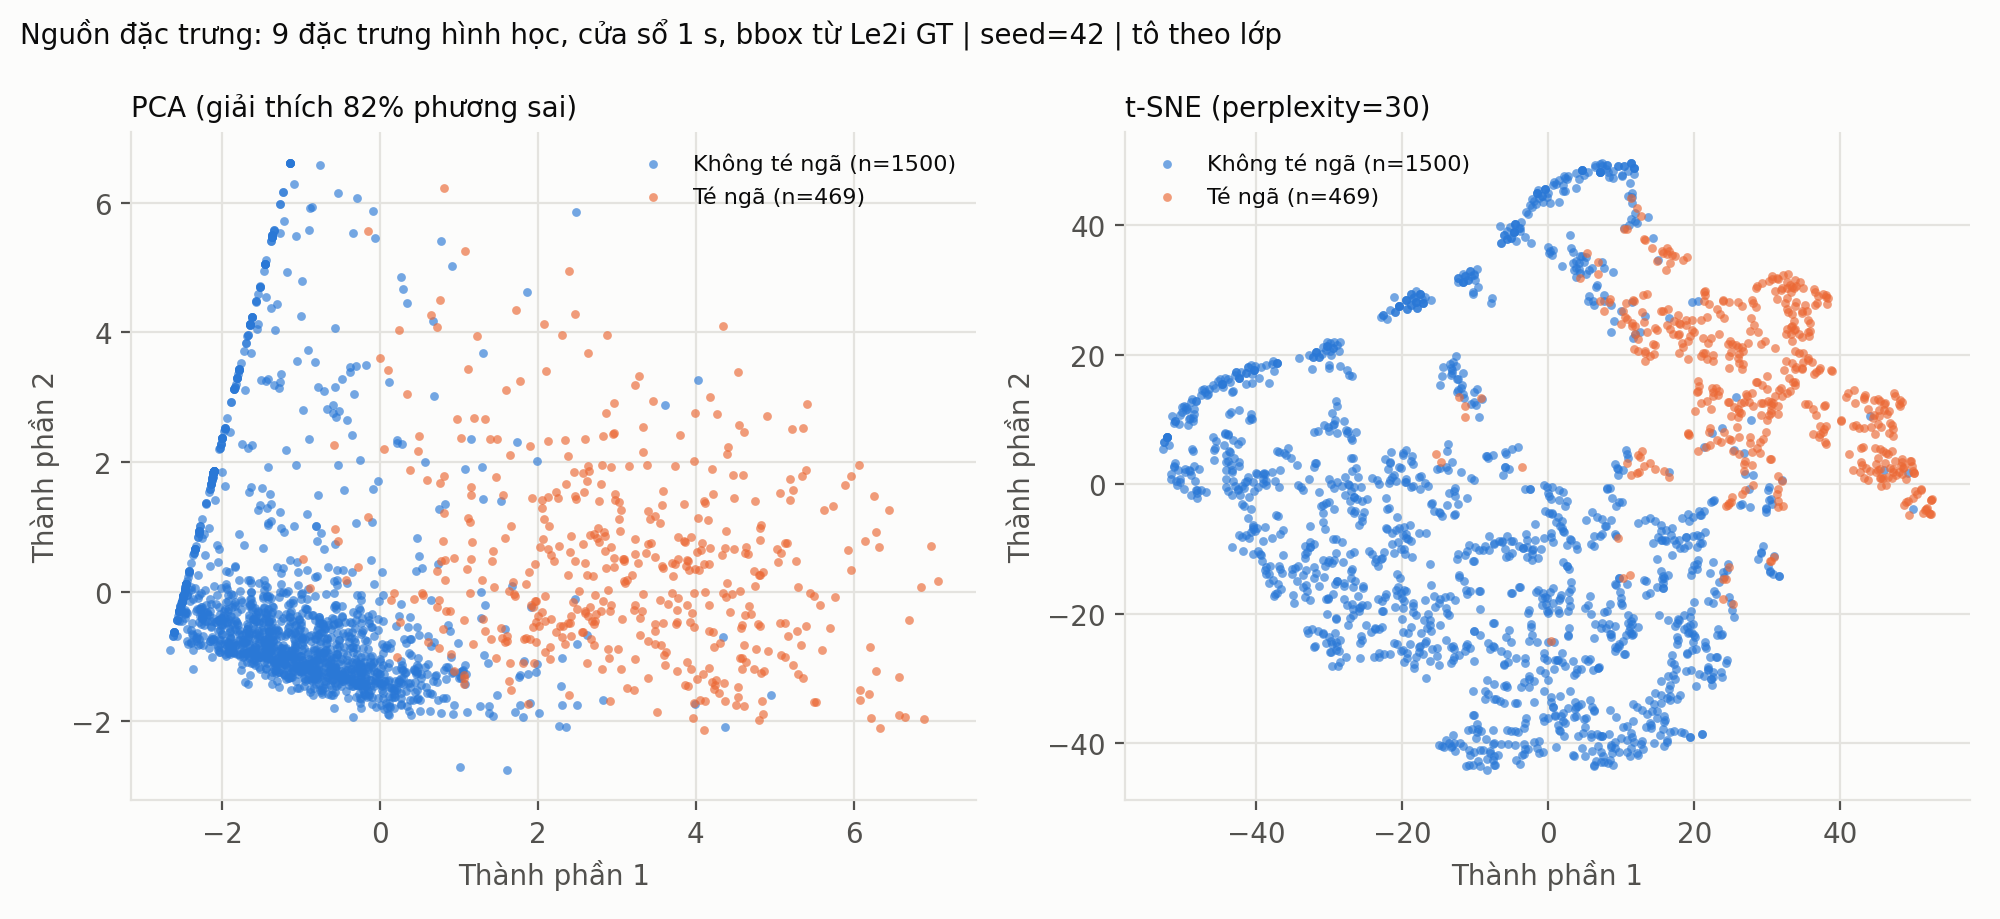

eda_5b_pca_tsne_by_size.png


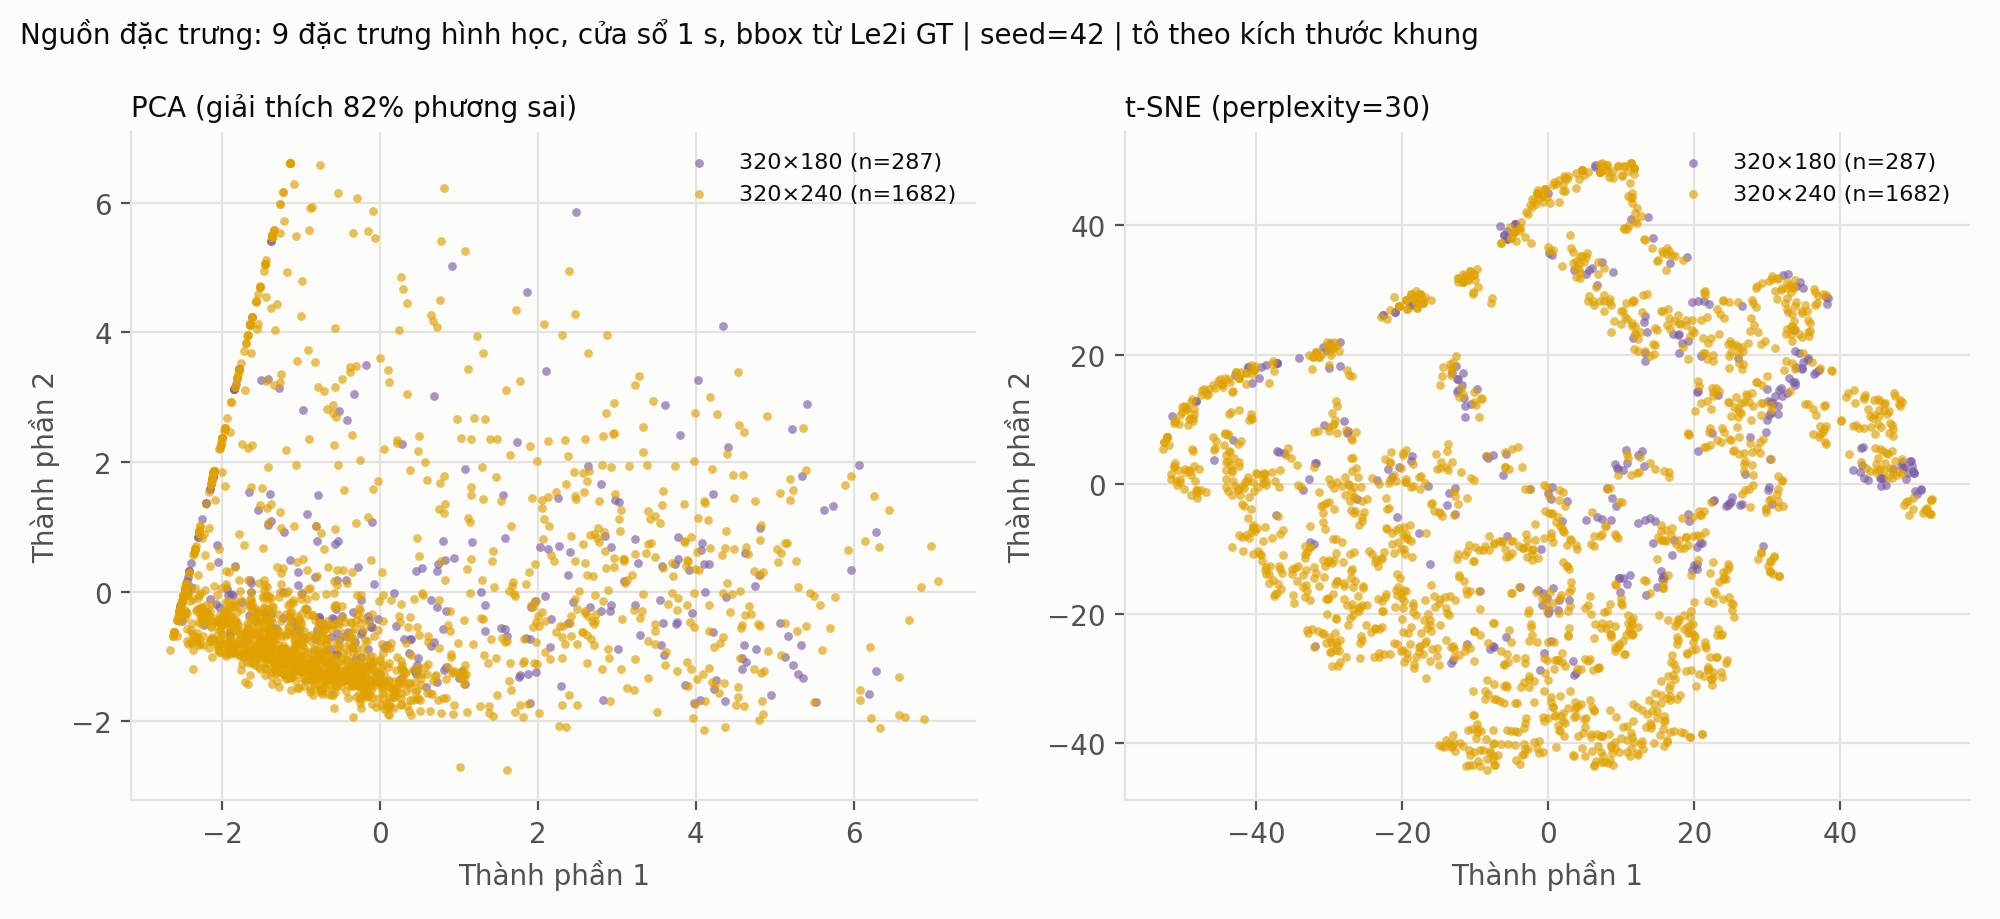

eda_6_le2i_scene_size.png


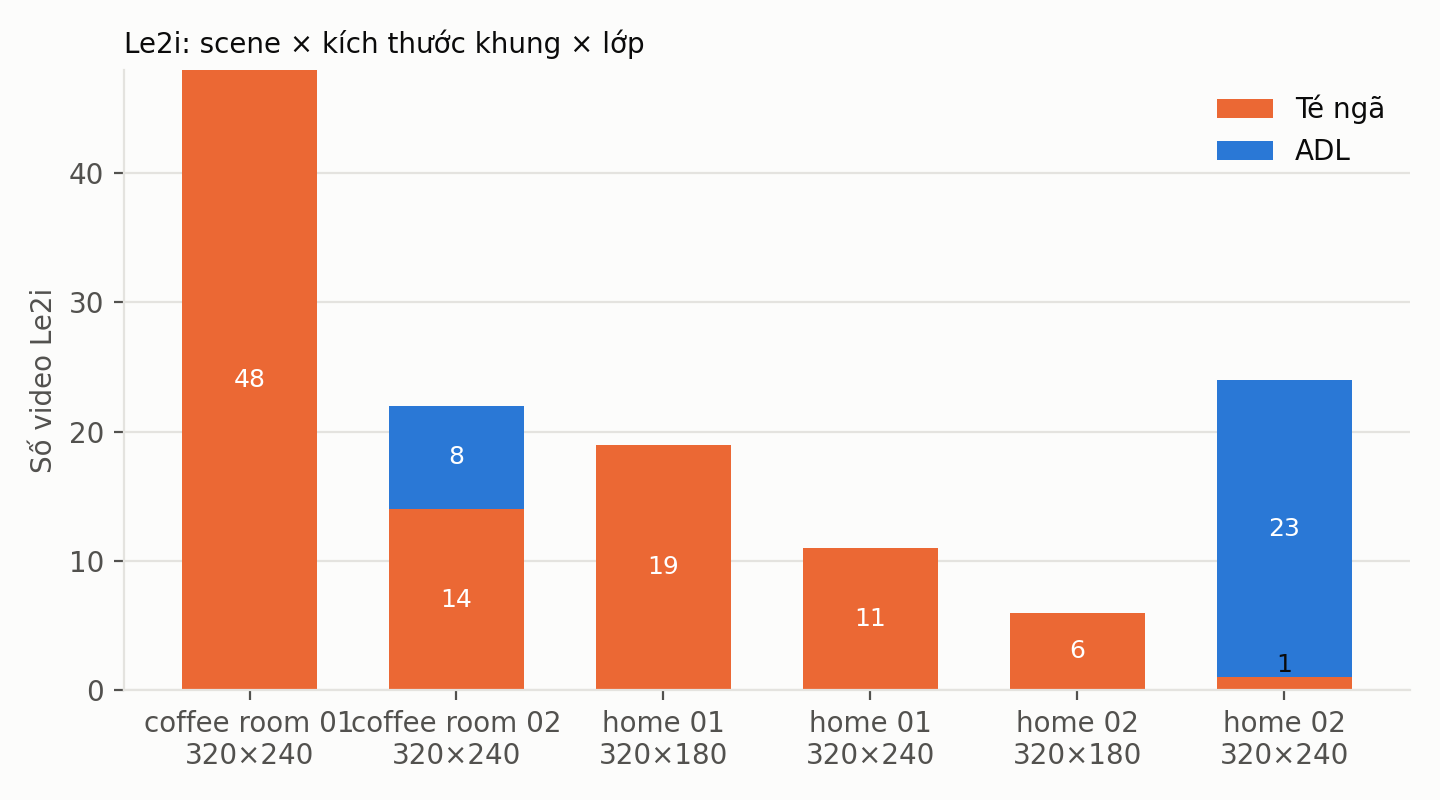

,scene,scene_part,size,fall,adl,total
0,coffee_room,01,320×240,48,0,48
1,coffee_room,02,320×240,14,8,22
2,home,01,320×180,19,0,19
3,home,01,320×240,11,0,11
4,home,02,320×180,6,0,6
5,home,02,320×240,1,23,24


{
  "n_windows": 6550,
  "sizes": [
    "320×180",
    "320×240"
  ],
  "silhouette_size": 0.11447378395897784,
  "centroid_distance": 0.33794373378760456,
  "silhouette_size_fall": 0.011542119217977634,
  "silhouette_label": 0.5210650574855021
}


In [8]:
from IPython.display import Image, display
import pandas as pd
for path in sorted(Path("reports/figures").glob("eda_*.png")):
    print(path.name)
    display(Image(str(path), width=720))
display(pd.read_csv("reports/results/le2i_scene_size_table.csv", dtype={"scene_part": str}))
print(Path("reports/results/size_separation.json").read_text())


## Hình minh họa tăng cường dữ liệu

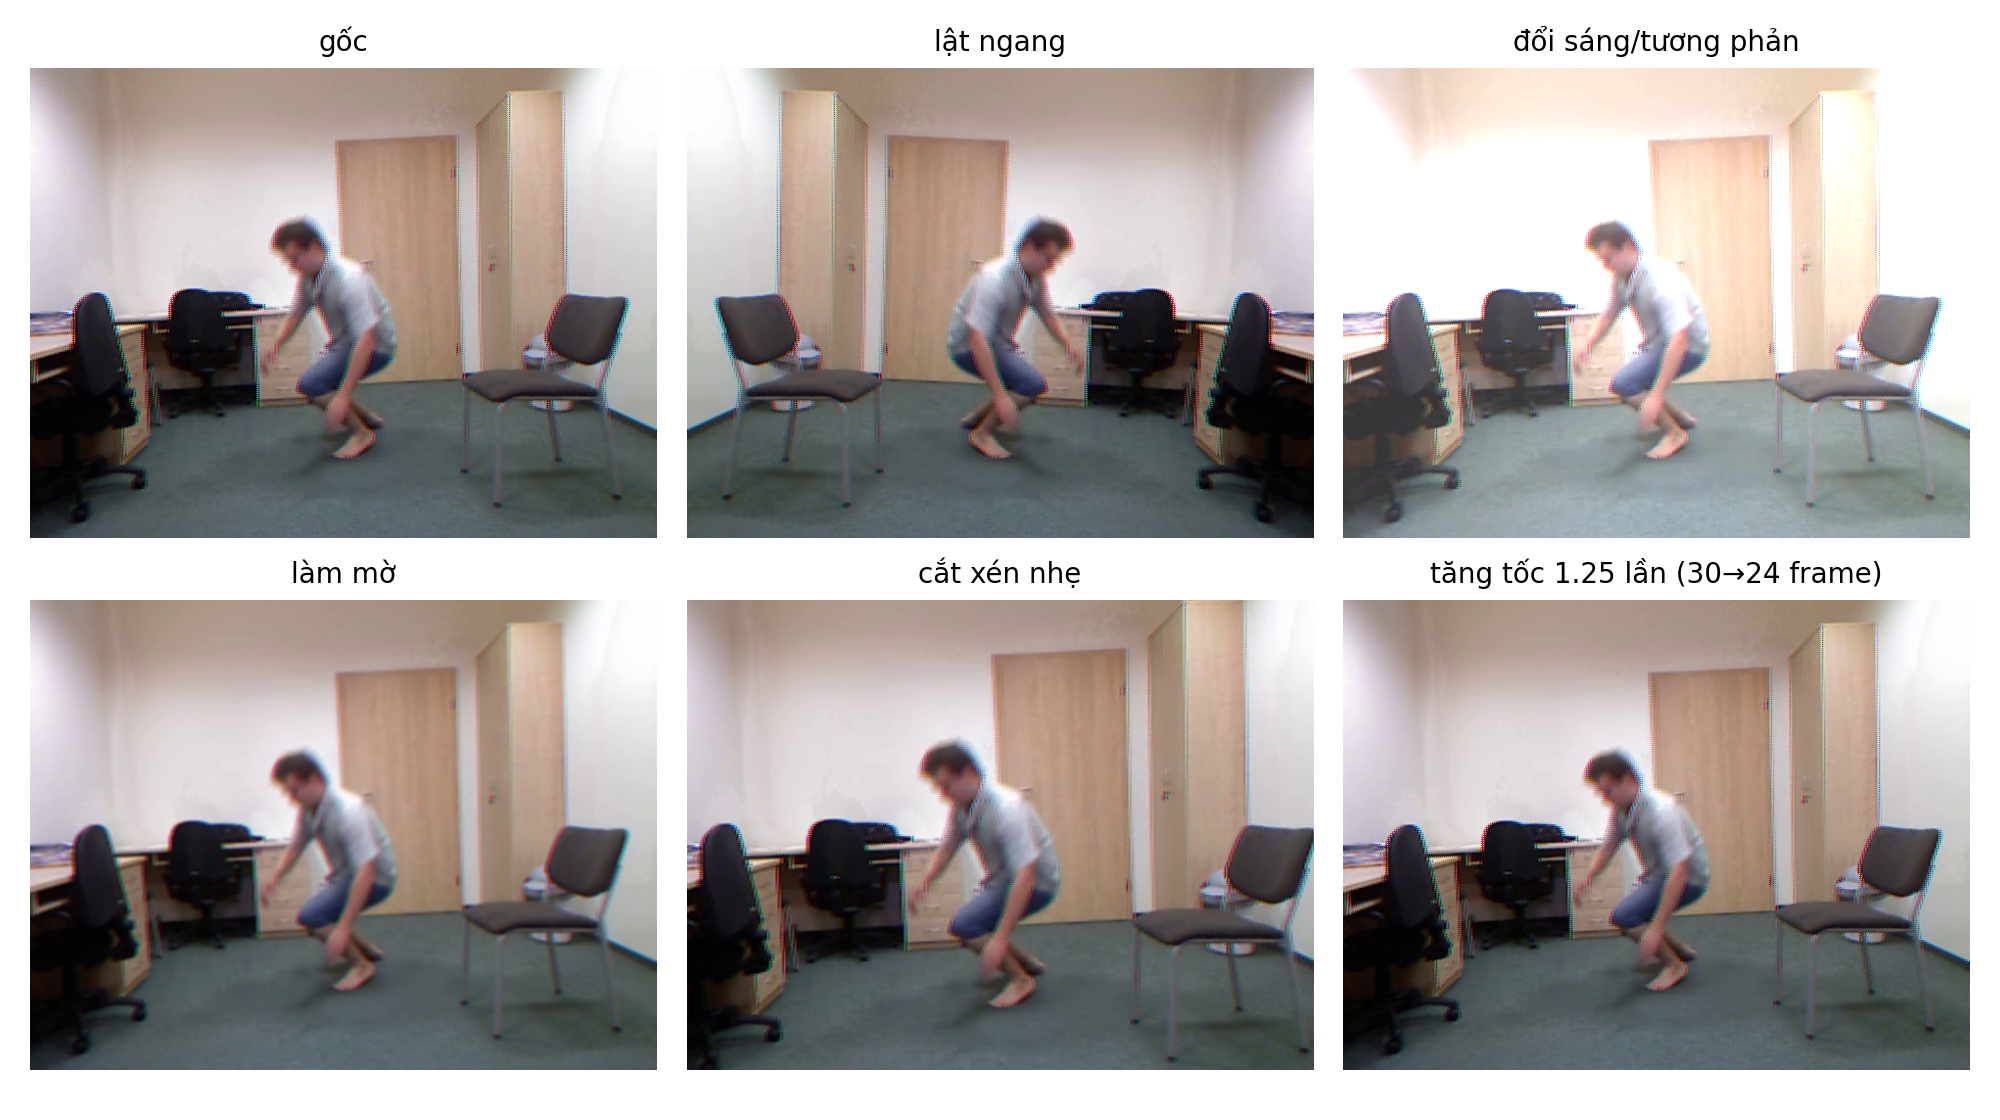

In [9]:
from src.data.augment import save_augment_preview
from src.data.loader import read_frames
row = meta[(meta["dataset"] == "urfd") & (meta["label"] == "fall")].iloc[0]
start = int(row["fall_start_frame"])
clip = read_frames(row["video_id"], start, start + 30, root=ROOT)
path = save_augment_preview(clip, "reports/figures/augment_demo.png")
display(Image(str(path), width=720))

Chạy xong, tải từ tab Output (thư mục `FallDetection`): `reports/figures/*.png` và `reports/results/*` commit vào `reports/` của repo; `DATA_CARD.md` (đã đủ nội dung dataset và khối kích thước) commit vào `dataset_index/`.